<a href="https://colab.research.google.com/github/KjelleJ/enkla-ai-experiment/blob/main/AIX_11_chatbot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---

# Orderbot till pizzeria
En enkel prototyp som använder ett API (programmeringsinterface) till den stora språkmodellen gemini-3.5-flash.
För att kunna använda api:et behöver du skapa en kostnadsfri API-nyckel till Gemini enligt följande anvisningar.

---



### 🔑 Instruktion för elever: Skapa en egen API-nyckel för Gemini

Följ dessa enkla steg för att skapa din egen kostnadsfria API-nyckel så att du kan köra din pizzeria-chatbot:

1. **Gå till Google AI Studio**
   Öppna webbläsaren och gå till [https://aistudio.google.com/](https://aistudio.google.com/).

2. **Logga in**
   Logga in med ditt vanliga Google-konto (t.ex. ditt skolkonto eller privata Gmail-konto).

3. **Skapa nyckeln (Get API Key)**
   * Klicka på den lilla nyckeln **"Get API key"** nere till vänster.
   * Klicka på **"Create API key"**.
   * Om du får välja projekt, välj **"Create API key in new project"**.

4. **Kopiera nyckeln**
   * En lång rad med bokstäver och siffror visas (din unika API-nyckel).
   * Klicka på **"Copy"** för att kopiera den. *Dela aldrig denna nyckel med någon annan!*

5. **Lägg till nyckeln i Google Colab**
   * Gå tillbaka till denna Google Colab-flik.
   * Klicka på **nyckelsymbolen (🔑 Secrets)** i menyn längst till vänster.
   * Klicka på **"Add new secret"**.
   * Under **Name** skriver du: `GOOGLE_API_KEY`
   * Under **Value** klistrar du in din kopierade API-nyckel.
   * Se till att aktivera bocken för **"Notebook access"** så att koden i din notebook kan läsa nyckeln.

Nu är du redo att köra koden och prata med din chatbot!

### 🍕 Skapa en Pizzeria-chatbot med Gemini API

Först installerar vi det officiella Python-SDK:t för Gemini (`google-genai`).

In [ ]:
!pip install google-genai

Nu kan vi hämta din API-nyckel från Colabs hemligheter, initiera klienten och starta en chatt med en **systeminstruktion** som beskriver hur chatboten ska bete sig (t.ex. sälja pizza, visa meny och vara trevlig).

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata

try:
    # Hämtar din API-nyckel från Colabs Secrets manager
    api_key = userdata.get('GOOGLE_API_KEY')
    client = genai.Client(api_key=api_key)
    print("Klienten har initierats framgångsrikt!")
except Exception as e:
    print("Fel: Kontrollera att du har lagt till GOOGLE_API_KEY i dina Secrets i Colab.")
    print(e)

Här startar vi en chatt-session där vi skickar med en systeminstruktion och skapar en enkel loop för att prata med boten direkt i Colab.

In [ ]:
system_instruction = """
Du är Mario, en trevlig och hjälpsam chatbot för pizzerian 'Bella Napoli'.
Din uppgift är att ta emot beställningar och svara på frågor om menyn.

Meny:
1. Margherita (Tomatsås, ost) - 95 kr
2. Vesuvio (Tomatsås, ost, skinka) - 105 kr
3. Capricciosa (Tomatsås, ost, skinka, svamp) - 115 kr
4. Rotmos med fläsklägg - 150 kr
Dryck: Läsk (Coca-Cola, Fanta, Sprite) - 25 kr

Håll dina svar korta, trevliga och på svenska. Fråga alltid efter kundens namn och om de vill hämta eller ha hemkörning när de beställer.
"""

# Vi använder den snabba och kostnadseffektiva modellen 'gemini-2.5-flash'
# Funkar inte för nya användare
model="gemini-3.5-flash"
chat = client.chats.create(
    model=model,
    config=types.GenerateContentConfig(
        system_instruction=system_instruction,
        temperature=0.7
    )
)

# Starta en kort testkonversation
response = chat.send_message("Hej! Vad har ni för pizzor?")
print("Bot:", response.text)

Om du vill köra en interaktiv chatt-loop där du kan skriva fritt i en textruta, kan du köra följande cell:

In [ ]:
# 1. Gör en beställning för avhämtning, fråga vad pizzerian heter, fråga om adressen...
# 2. Gör en beställning för leverans
# 3. Begär ett förslag till en kort AI-kurs

print("Skriv 'avsluta' för att stänga chatten.\n")
while True:
    user_input = input("Du: ")
    if user_input.lower() == 'avsluta':
        print("Chatten avslutad.")
        break

    response = chat.send_message(user_input)
    print(f"Bot: {response.text}\n")

#En app för Bella Napoli
---
#####En vanlig användare kan inte köra våran bot via Colab. Vi behöver en app, helst en webbapp som kan köras i webbläsaren. Jag bad Gemini att göra en sådan app. Vi vill inte exponera vår API-nyckel för en användare av appen. Därför kommunicerar själva appen (index.html) med en PHP-proxy (api.php) som innehåller API-nyckeln och kommunicerar med Gemini (vår LLM). api.php laddas aldrig ner till användaren.
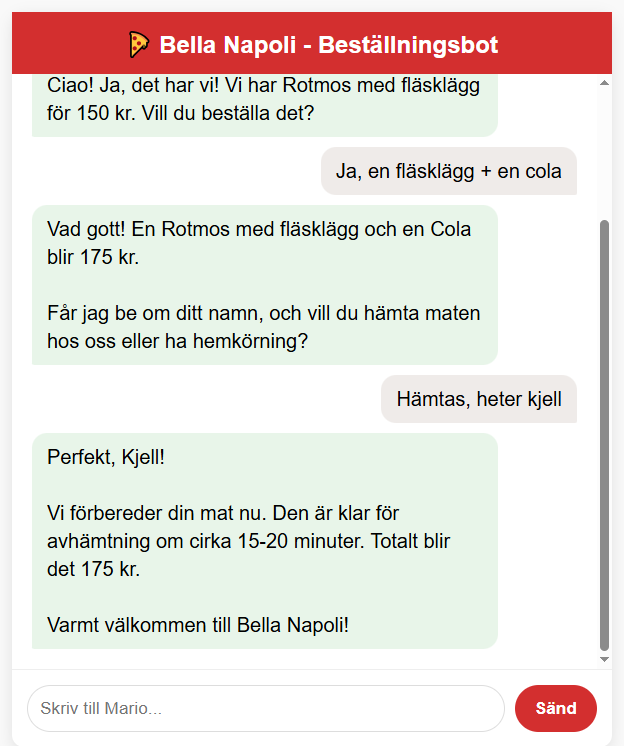
---

---

